## Dependencies

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
from IPython.display import display
from pdf2image import convert_from_path

In [3]:
import sys
sys.path.append('../libs')

%load_ext autoreload
%autoreload 2

import ios

## Setup

In [4]:
VERSION = 2
VAR_X = ['mean', 'median', 'mode']
DIR = f'../../results/v{VERSION}/chinese_gender/comparison/regression/_<VAR_X>'

## Data

In [5]:
df_results_mean = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mean'))
df_results_median = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'median'))
df_results_mode = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mode'))
df_results = pd.concat([df_results_mean, df_results_median, df_results_mode], ignore_index=True)
df_results.shape

(765, 18)

In [6]:
cols = ['y','features_id','train_eval','test_r2','test_rmse']
df_results[cols].sort_values('test_rmse', ascending=True)

,y,features_id,train_eval,test_r2,test_rmse
13,mean,50,0.087188,0.868647,0.110648
95,mean,42,0.094558,0.864589,0.112344
196,mean,9,0.101891,0.858811,0.114716
109,mean,49,0.079042,0.858044,0.115027
73,mean,48,0.096974,0.855934,0.115879
...,...,...,...,...,...
611,mode,16,0.145810,0.365885,0.284863
643,mode,74,0.137205,0.361596,0.285825
725,mode,2,0.309217,0.263288,0.307044
504,median,1,0.129412,0.221170,0.307893


In [7]:
best_id = df_results.test_rmse.idxmin()
best_id

13

In [8]:
df_results.loc[best_id]

y                                                              mean
features_id                                                      50
features             ['ngender_r', 'gender_nw', 'mean_ngender_rnw']
nfeatures                                                         3
cat_features                                            [gender_nw]
best_params       {'depth': 2, 'learning_rate': 0.1, 'l2_leaf_re...
best_score        {'learn': {'RMSE': 0.08718829199059108}, 'vali...
best_iteration                                                  165
test_size                                                       0.2
random_state                                                  12345
loss_function                                                  RMSE
eval_metric                                                    RMSE
train_eval                                                 0.087188
test_r2                                                    0.868647
test_rmse                                       

In [9]:
df_results.loc[best_id].features

# "['mean_ngender_rw', 'median_ngender_rw', 'mode_ngender_rw']"
# "['ngender_r', 'gender_w_female', 'gender_w_male', 'mean_ngender_rw']"

df_results.loc[best_id].features

"['ngender_r', 'gender_nw', 'mean_ngender_rnw']"

In [10]:
f_name = DIR.replace('<VAR_X>',df_results.loc[best_id].y) 
f_name = f"{f_name}/{df_results.loc[best_id].y}_{df_results.loc[best_id].features_id}"
f_name

'../../results/v2/chinese_gender/comparison/regression/_mean/mean_50'

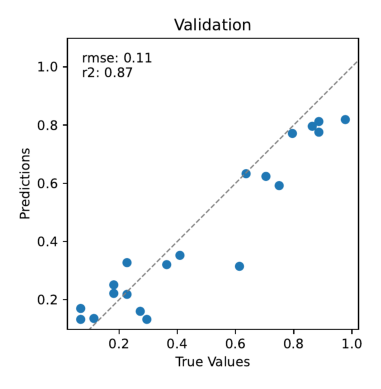

In [11]:
# predictions
fn = f"{f_name}_predictions_val.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



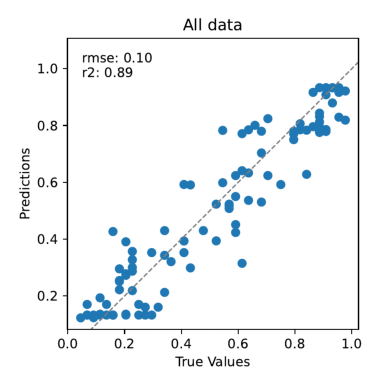

In [12]:
# predictions
fn = f"{f_name}_predictions_all.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



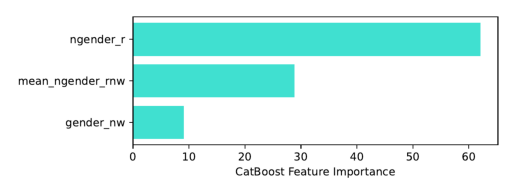

In [15]:
# predictions
fn = f"{f_name}_feature_importance.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



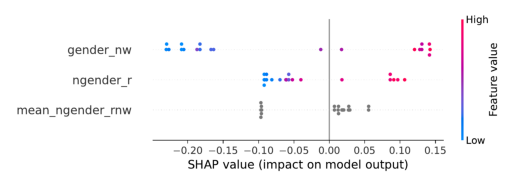

In [16]:
# predictions
fn = f"{f_name}_shap.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()

